# Exercici d'arbres de decisió per a Regressió


Aquest conjunt de dades s'utilitza per dur a terme anàlisis energètiques a partir de simulacions de 12 formes d'edificis diferents realitzades amb el programari Ecotect. El model considera variables clau com l'àrea envidrada, la seua distribució i l'orientació, entre altres paràmetres, generant un total de **768 mostres** amb **8 característiques** cadascuna.

* **Objectiu principal:** Predir dos valors reals continus (relacionats amb l'eficiència energètica de l'edifici).

De la fitxa tècnica del dataset: 

The dataset contains eight attributes (or features, denoted by X1…X8) and two responses (or outcomes, denoted by y1 and y2). The aim is to use the eight features to predict each of the two responses.

Specifically: 
* X1 Relative Compactness 
* X2 Surface Area 
* X3 Wall Area 
* X4 Roof Area 
* X5 Overall Height 
* X6 Orientation 
* X7 Glazing Area 
* X8 Glazing Area Distribution 

* y1 Heating Load 
* y2 Cooling Load

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('ENB2012_data.csv') 
df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


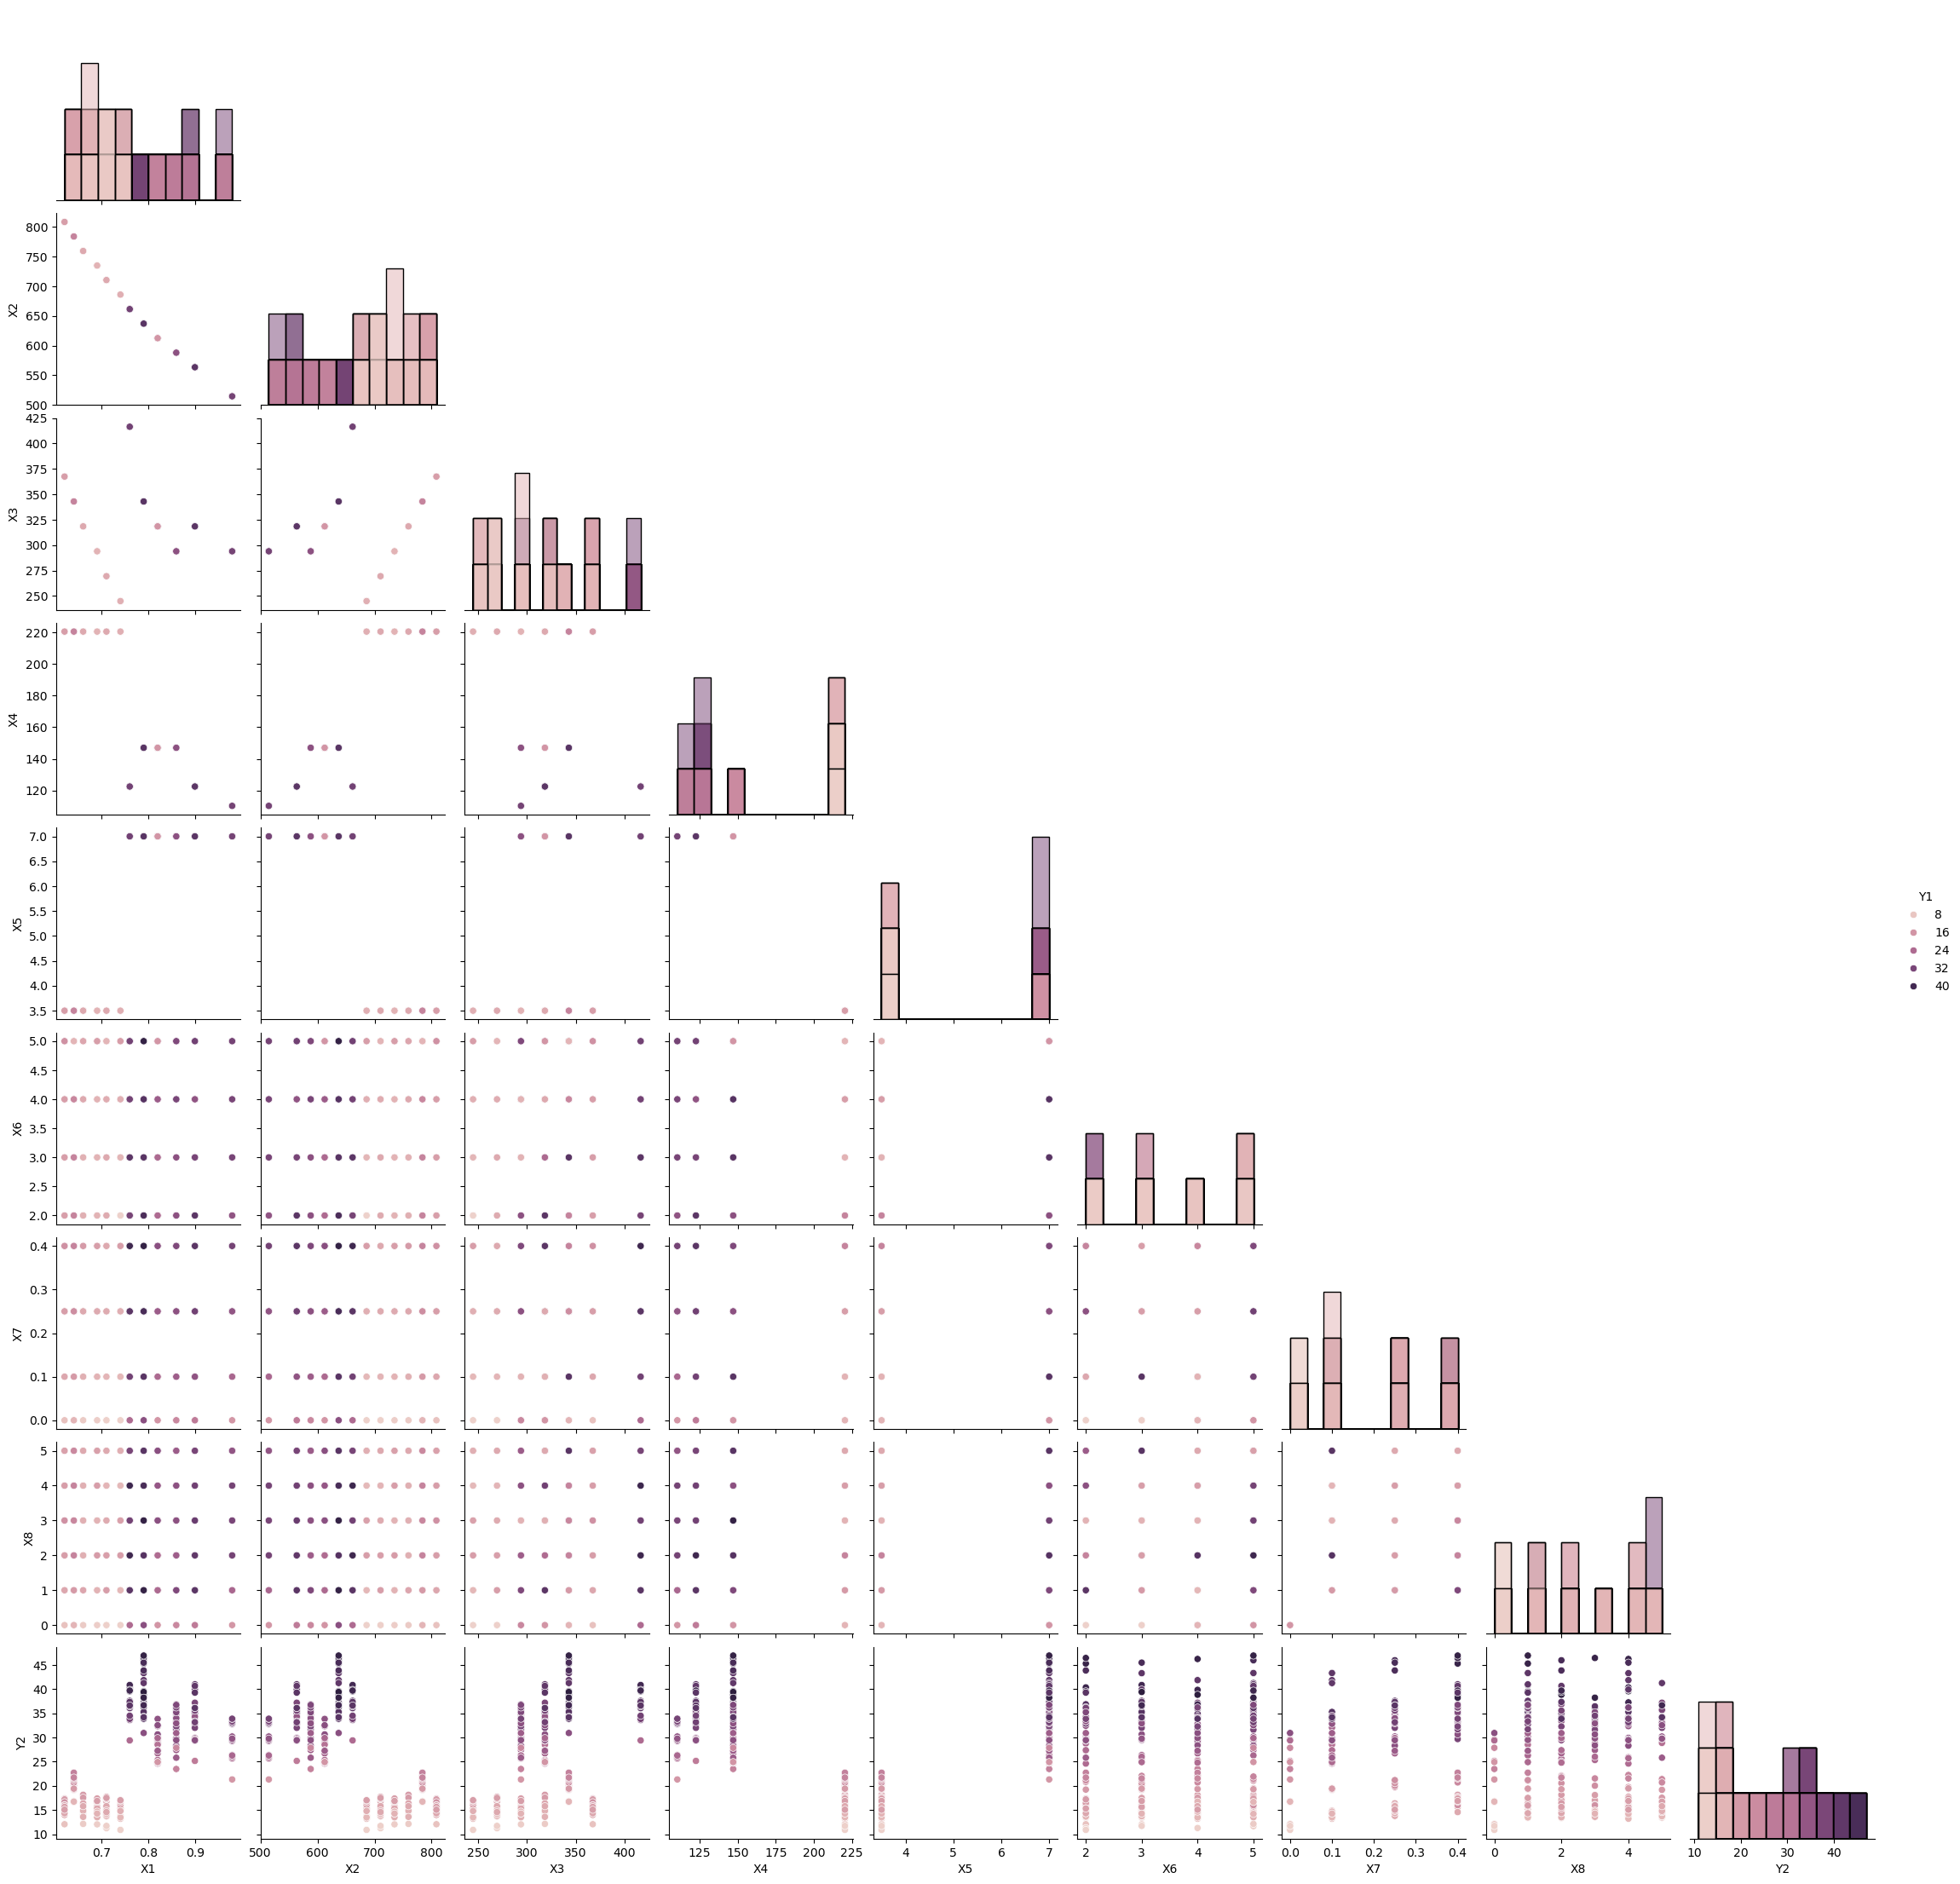

In [15]:
sns.pairplot(df.sample(n=300, random_state=42), hue='Y1', diag_kind='hist', corner=True)

<Axes: >

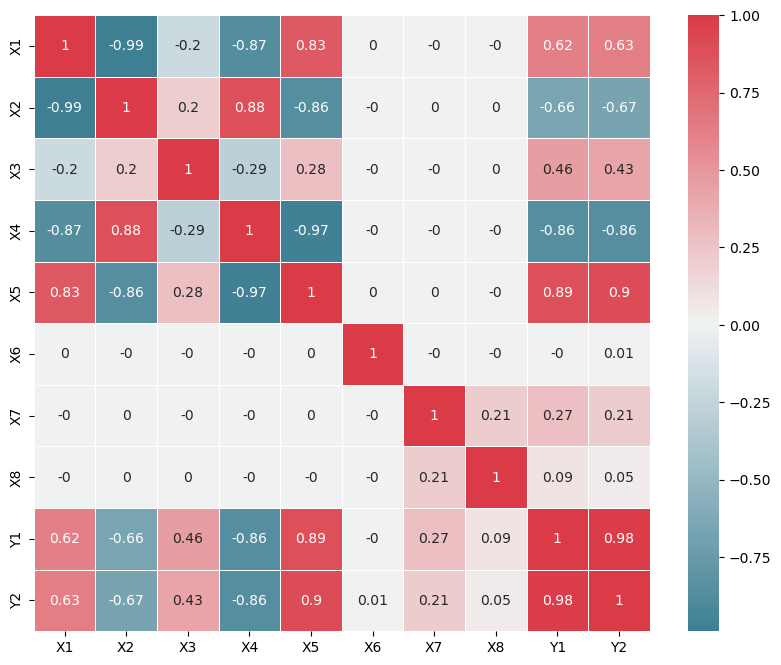

In [8]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr().round(2), square=True, annot=True, linewidths=.5, cmap=sns.diverging_palette(220, 10, as_cmap=True))

In [34]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_squared_error, mean_absolute_error

for y_label in ["Y1","Y2"]:
    X_train, X_test, y_train, y_test = train_test_split(
        df.drop(["Y1","Y2"],axis=1), df[y_label], test_size=0.2, random_state=42
    ) 

    tree_reg = DecisionTreeRegressor(max_depth=5)
    tree_reg.fit(X_train, y_train)
    y_pred = tree_reg.predict(X_test)
    print("\nMètriques del Model Arbre de Decisió per a:",y_label)
    # Avaluar el model utilitzant mètriques
    mse = mean_squared_error(y_test, y_pred)  # Calcular l'Error Quadràtic Mitjà (MSE)
    mae = mean_absolute_error(y_test, y_pred)
    print(f"  MAE: {mae:.4f}")  # Imprimir l'MAE amb 4 decimals
    print(f"  MSE: {mse:.4f}")  # Imprimir l'MSE amb 4 decimals
    rmse = np.sqrt(mse)  # Calcular l'Arrel de l'Error Quadràtic Mitjà (RMSE)
    print(f"  RMSE: {rmse:.4f}")  # Imprimir l'RMSE amb 4 decimals
    r2 = r2_score(y_test, y_pred)  # Calcular el Coeficient de Determina
    print("  R2:",r2)


Mètriques del Model Arbre de Decisió per a: Y1
  MAE: 0.7561
  MSE: 1.2229
  RMSE: 1.1059
  R2: 0.9882670371295307

Mètriques del Model Arbre de Decisió per a: Y2
  MAE: 1.1931
  MSE: 3.6433
  RMSE: 1.9087
  R2: 0.9606801487989102


In [35]:
X_train, X_test, y_train, y_test = train_test_split(
        df.drop(["Y1","Y2"],axis=1), df[["Y1","Y2"]], test_size=0.2, random_state=42
) 

tree_reg = DecisionTreeRegressor(max_depth=5)
tree_reg.fit(X_train, y_train)
y_pred = tree_reg.predict(X_test)
print("\nMètriques del Model Arbre de Decisió per a Y1 Y2")
 # Avaluar el model utilitzant mètriques
mse = mean_squared_error(y_test, y_pred)  # Calcular l'Error Quadràtic Mitjà (MSE)
mae = mean_absolute_error(y_test, y_pred)
print(f"  MAE: {mae:.4f}")  # Imprimir l'MAE amb 4 decimals
print(f"  MSE: {mse:.4f}")  # Imprimir l'MSE amb 4 decimals
rmse = np.sqrt(mse)  # Calcular l'Arrel de l'Error Quadràtic Mitjà (RMSE)
print(f"  RMSE: {rmse:.4f}")  # Imprimir l'RMSE amb 4 decimals
r2 = r2_score(y_test, y_pred)  # Calcular el Coeficient de Determina
print("  R2:",r2)

# Obtenir el R² per a cada variable per separat
r2_per_var = r2_score(y_test, y_pred, multioutput="raw_values")

print(f"  R² per a Y1: {r2_per_var[0]:.4f}")
print(f"  R² per a Y2: {r2_per_var[1]:.4f}")


Mètriques del Model Arbre de Decisió per a Y1 Y2
  MAE: 1.0161
  MSE: 2.4385
  RMSE: 1.5616
  R2: 0.9744726361582088
  R² per a Y1: 0.9873
  R² per a Y2: 0.9616


> Interpreta els resultats de cadascuna de les cel·les de codi per exposar a la classe i debatir. 
> Fes un bucle de 2 a 10 per avaluar la millor profunditat per a aquest cas en concret en multieixida. 